<a href="https://colab.research.google.com/github/EmilKarimov3/CSCE1015/blob/main/Copy_of_INFO4670_Assignment_SMS_Spam_v4_Emil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [17]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> I believe that a false positive is more problematic since it may block a legitimate message. This may result in a user missing a validation code or a business message regarding work. A false negative would allow spam to reach the user and while this is annoying it may also lead to scams reaching the user

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> I would use precision as the main measure. I don't want spam messages to not be identified as spam. The higher the precision the less non-spam messages that will be filtered out. I would also look at recall to ensure that some spam is still picked up

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> A model that only ever predicts ham will perform 87% of the time. However this is not a very useful spam classifier as it will fail to recall any spam emails. This model will have a zero spam recall and a zero F1 score


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [18]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


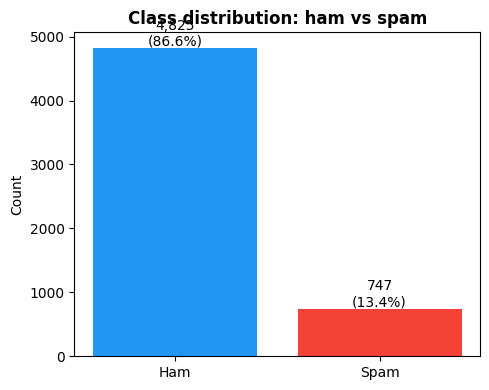

In [19]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [20]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


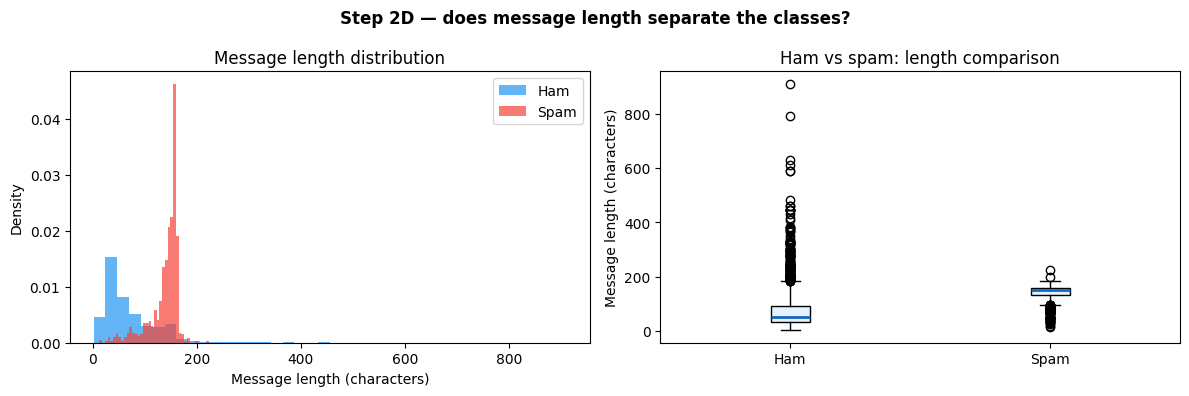

In [21]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [22]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [23]:
def build_features_v2(df):
    d = build_features(df)
    msg = d['message'].str.lower()

    # Detect links
    d['has_url'] = msg.str.contains(
        r'https?://|www\.', regex=True
    ).astype(int)

    # Detect requests to text or reply
    d['has_reply'] = msg.str.contains(
        r'\b(?:txt|text|reply)\b', regex=True
    ).astype(int)

    return d

df = build_features_v2(raw)

feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)

for feat in feature_cols:
    sp = df[df['spam'] == 1][feat].mean()
    ha = df[df['spam'] == 0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                14.2%    0.0%  +14.1%
has_reply              40.7%    2.5%  +38.2%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


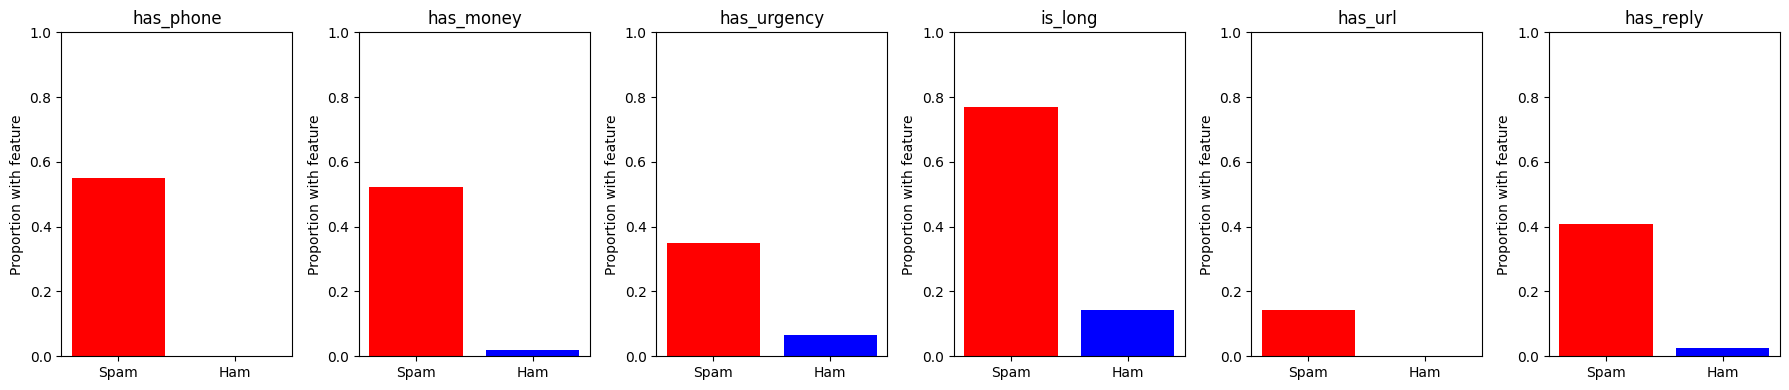

In [24]:
n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(18, 4))

for ax, feat in zip(axes, feature_cols):
    spam_rate = df.loc[df['spam'] == 1, feat].mean()
    ham_rate = df.loc[df['spam'] == 0, feat].mean()

    ax.bar(['Spam', 'Ham'], [spam_rate, ham_rate],
           color=['red', 'blue'])
    ax.set_title(feat)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Proportion with feature')

plt.tight_layout()
plt.show()


### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> Checks for “www.”, “https://” or “http://” in a message. I hoped this would be useful as spams might contain links to phishing or promotional pages

*Feature 2 — name and explanation:*
> Checks for text, text or reply, or txt. These may be indicative of spam since spam might request a reaction to an offer. However, they may also appear in normal messages

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> is_long has the largest separation (approximately 62.7 percentage points). 76.8% of spam contains is_long compared to only 14.2% of ham. Large separations can be useful in reducing uncertainty and in separating the classes. This is the basis for Information Gain. Having the largest separation does not, however, necessarily imply that a given attribute will be the root attribute.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> For example: “Your delivery address requires verification. Please update your address at parcel-check.example.” This URL is not caught by the has_url attribute since it does not contain “www,” “http,” or “https.” Furthermore, the text contains no phone number, no money related words, no urgency words, “txt,” “text” or “reply.” The text is also less than 130 characters. All six attributes would equal zero and this piece of spam could go undetected


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [25]:
X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f'Training set: {len(y_train):,} messages')
print(f'Test set: {len(y_test):,} messages')
print(f'Training spam rate: {y_train.mean():.1%}')
print(f'Test spam rate: {y_test.mean():.1%}')


Training set: 4,179 messages
Test set: 1,393 messages
Training spam rate: 13.4%
Test spam rate: 13.4%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> We set stratify=y in order to have about the same proportion of spam and ham in both datasets. If this is not done then there may be a small number of spam messages in one of the datasets which would make evaluation or training problematic

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> For small datasets I'd recommend cross-validation as a single train/test division may yield extreme results (either too good or too bad). Multiple test divisions will give a more accurate indication of performance


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 14


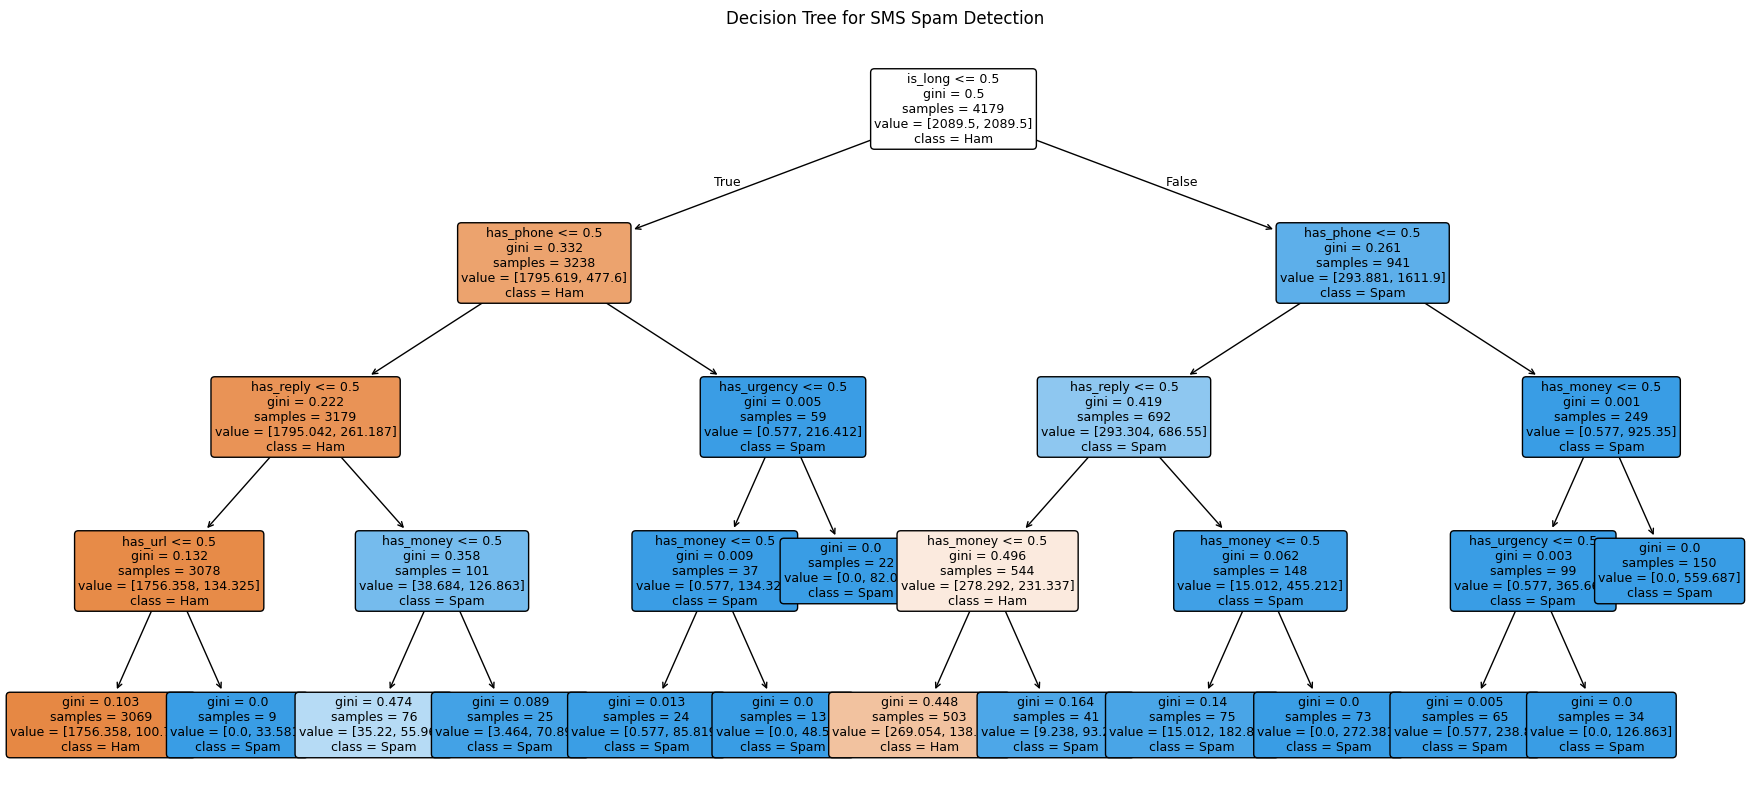

Decision Tree rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- cla

In [26]:
dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight='balanced'
)

dt.fit(X_train, y_train)

print(f'Number of leaves: {dt.get_n_leaves()}')

plt.figure(figsize=(22, 10))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=['Ham', 'Spam'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree for SMS Spam Detection')
plt.show()

print('Decision Tree rules:')
print(export_text(dt, feature_names=feature_cols))


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


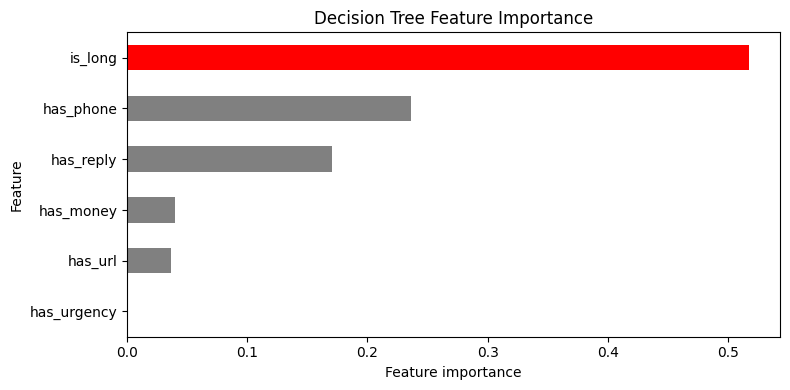

is_long        0.517271
has_phone      0.236019
has_reply      0.170684
has_money      0.039595
has_url        0.036429
has_urgency    0.000002
dtype: float64

Root feature: is_long


In [27]:
importance = pd.Series(
    dt.feature_importances_,
    index=feature_cols
).sort_values()

colors = [
    'red' if feature == importance.idxmax() else 'gray'
    for feature in importance.index
]

importance.plot(
    kind='barh',
    color=colors,
    figsize=(8, 4)
)

plt.xlabel('Feature importance')
plt.ylabel('Feature')
plt.title('Decision Tree Feature Importance')
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False))
print(f'\nRoot feature: {feature_cols[dt.tree_.feature[0]]}')


### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


Max depth  Train F1  Test F1     Gap
        1    0.5756   0.5646  0.0110
        2    0.6282   0.6210  0.0073
        3    0.8272   0.8347 -0.0075
        4    0.8500   0.8527 -0.0027
        5    0.8617   0.8615  0.0002
        6    0.8591   0.8593 -0.0003
Unlimited    0.8591   0.8593 -0.0003


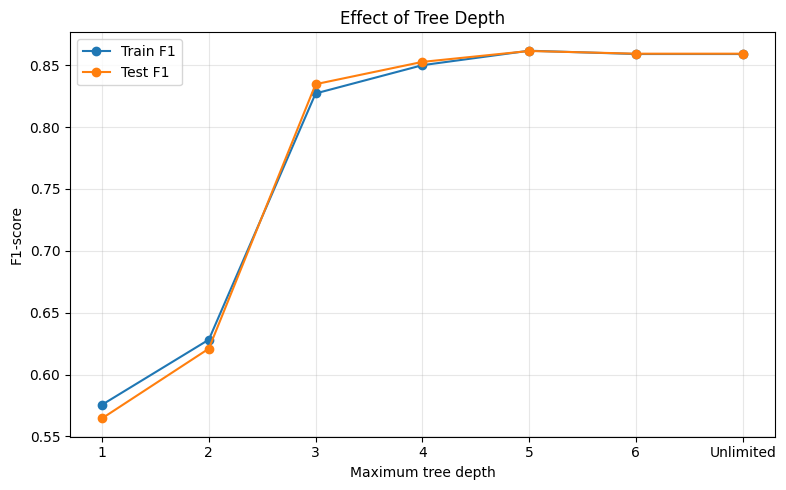

In [28]:
depths = [1, 2, 3, 4, 5, 6, None]
train_f1 = []
test_f1 = []

for depth in depths:
    depth_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42,
        class_weight='balanced'
    )
    depth_model.fit(X_train, y_train)

    train_f1.append(
        f1_score(y_train, depth_model.predict(X_train))
    )
    test_f1.append(
        f1_score(y_test, depth_model.predict(X_test))
    )

depth_labels = [str(d) if d is not None else 'Unlimited'
                for d in depths]

results_depth = pd.DataFrame({
    'Max depth': depth_labels,
    'Train F1': train_f1,
    'Test F1': test_f1
})
results_depth['Gap'] = results_depth['Train F1'] - results_depth['Test F1']

print(results_depth.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(depth_labels, train_f1, marker='o', label='Train F1')
plt.plot(depth_labels, test_f1, marker='o', label='Test F1')
plt.xlabel('Maximum tree depth')
plt.ylabel('F1-score')
plt.title('Effect of Tree Depth')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


There is little difference between the training and test scores at each depth and there doesn’t appear to be a depth at which the difference begins to grow significantly. The test F1 score appears to be at its peak (0.8615) at depth 5 before declining at depths 6 and unlimited. There doesn’t appear to be much sign of overfitting in these results

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [29]:
nb = BernoulliNB()
nb.fit(X_train, y_train)

print('Naive Bayes training complete!')


Naive Bayes training complete!


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


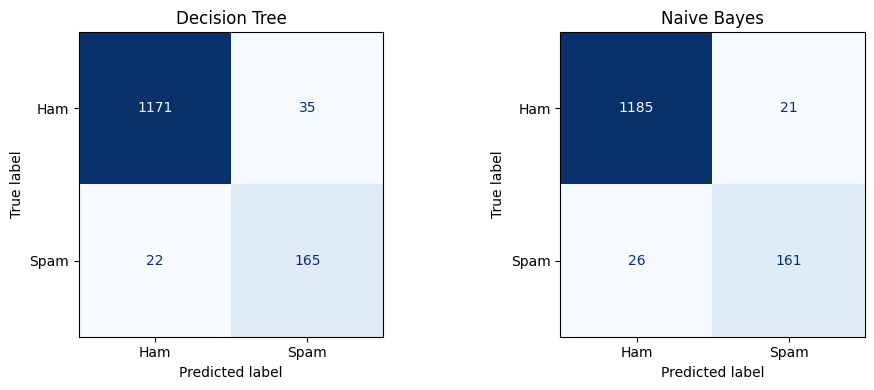

Decision Tree: TP=165, FP=35, FN=22, TN=1171
Naive Bayes: TP=161, FP=21, FN=26, TN=1185


In [30]:
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, predictions in zip(
    axes,
    ['Decision Tree', 'Naive Bayes'],
    [y_pred_dt, y_pred_nb]
):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Ham', 'Spam']
    ).plot(ax=ax, cmap='Blues', colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

for name, predictions in [
    ('Decision Tree', y_pred_dt),
    ('Naive Bayes', y_pred_nb)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    print(f'{name}: TP={tp}, FP={fp}, FN={fn}, TN={tn}')


### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree    0.9591     0.8250  0.8824    0.8527
  Naive Bayes    0.9663     0.8846  0.8610    0.8726


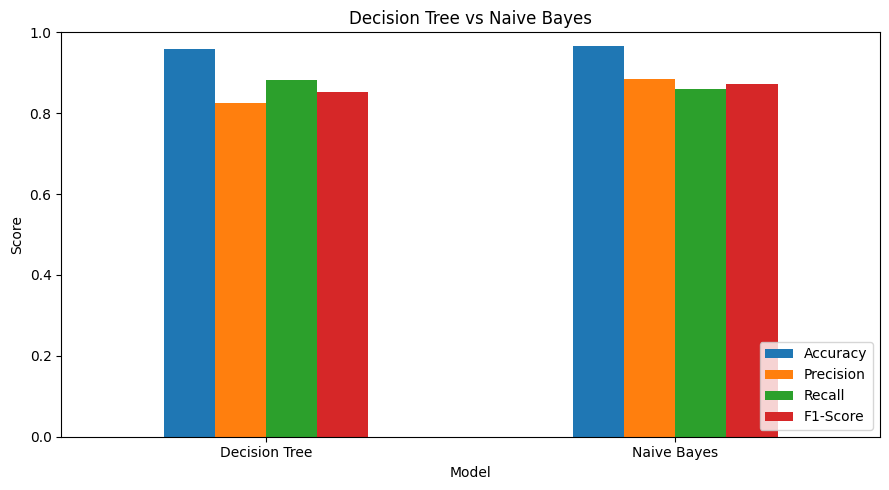

In [31]:
rows = []

for name, predictions in [
    ('Decision Tree', y_pred_dt),
    ('Naive Bayes', y_pred_nb)
]:
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0)
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

metrics_df.set_index('Model').plot(
    kind='bar',
    figsize=(9, 5),
    rot=0
)
plt.ylabel('Score')
plt.ylim(0, 1)
plt.title('Decision Tree vs Naive Bayes')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in [
    ('Decision Tree', dt),
    ('Naive Bayes', nb)
]:
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring='f1'
    )
    print(f'{name} — Average CV F1: {scores.mean():.4f}')


Decision Tree — Average CV F1: 0.8502
Naive Bayes — Average CV F1: 0.8858


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> The Decision Tree correctly caught 165 spam messages (TP), missed 22 spam messages (FN), and wrongly blocked 35 legitimate messages (FP)

*Naive Bayes:*
> Naive Bayes correctly caught 161 spam messages (TP), missed 26 spam messages (FN), and wrongly blocked 21 legitimate messages (FP)

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> I have used precision as the evaluation metric. Naive Bayes has a higher precision (88.46%) than Decision Tree (82.50%) by a difference of 5.96 points. Naive Bayes also performs better on cross-validation with an average F1 value of 0.8858 vs. 0.8502. While this helps in recommending Naive Bayes, it does not necessarily indicate an advantage in precision since a different metric (F1) was used in cross-validation

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I would suggest Naive Bayes since the aim is to give protection for legitimate messages. Naive Bayes gave 88.46% accuracy and blocked 21 legitimate messages compared to 35 from the Decision Tree. However it failed to identify 26 spam messages, 4 more than the Decision Tree. I could improve the URL token to identify URLs that do not contain either “www” or “http” and then re run the program to see if a greater amount of spam is identified without a result in a number of legitimate messages being blocked

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> My has_url field does not account for newer spam which omits http, https and www. My has_url field also does not allow me to determine if a url is good or bad. My has_reply field does not account for spam that appears legitimate but requests account verification or delivery confirmation without the words reply, text or txt.
